# Question to Answer:
***How do the casual members and annual members use the bike-sharing service differently?***

In [1]:
import pandas as pd

In [2]:
data = pd.read_csv('bike_share_cleaned.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3817991 entries, 0 to 3817990
Data columns (total 12 columns):
 #   Column             Dtype
---  ------             -----
 0   trip_id            int64
 1   start_time         str  
 2   end_time           str  
 3   bikeid             int64
 4   tripduration       int64
 5   from_station_id    int64
 6   from_station_name  str  
 7   to_station_id      int64
 8   to_station_name    str  
 9   usertype           str  
 10  ride_length        int64
 11  day_of_week        int64
dtypes: int64(7), str(5)
memory usage: 349.5 MB


In [3]:
# no. of casual and annual members
data['usertype'].value_counts()

usertype
Member    2937360
Casual     880631
Name: count, dtype: int64

In [4]:
# Percentage of annual vs casual members 
riders = dict(data['usertype'].value_counts())
total = riders['Member']+riders['Casual']
for rider, count in riders.items():
    print(f"{rider}: {(count/total)*100:.2f}%")

Member: 76.93%
Casual: 23.07%


In [5]:
data.groupby(['usertype','day_of_week']).count()['trip_id']

usertype  day_of_week
Casual    0              101489
          1               88655
          2               89745
          3              101372
          4              121141
          5              208056
          6              170173
Member    0              458780
          1              497025
          2              494277
          3              486915
          4              456966
          5              287163
          6              256234
Name: trip_id, dtype: int64

In [6]:
# apply custome function to dataframe to distinguish the weekdays and weekend.
data['day_type'] = data['day_of_week'].apply(lambda x: 'Weekend' if x > 4 else 'Weekday')

In [7]:
data['day_type'].value_counts()

day_type
Weekday    2896365
Weekend     921626
Name: count, dtype: int64

In [8]:
pd.crosstab(data['usertype'], data['day_type']) # cross tabulation of usertype vs daytype

day_type,Weekday,Weekend
usertype,,
Casual,502402,378229
Member,2393963,543397


In [9]:
pd.crosstab(data['usertype'], data['day_type'], normalize='index') * 100

day_type,Weekday,Weekend
usertype,,
Casual,57.050229,42.949771
Member,81.500497,18.499503


In [10]:
# weekdays (day: 0-4), weekend (day: 5,6)
# as we can see above members rides most on weekdays vs casuals rides most on weekends.

In [11]:
# calculate mean, median of ride_length per usertype
data.groupby('usertype')['ride_length'].agg(['mean','median'])

,mean,median
usertype,,
Casual,3421.081143,1550.0
Member,859.668071,588.0


In [12]:
# so members have less mean, median time than casuals. which means that members rides comparatively less distance per trip than casuals.

## Visual summaries of the two findings

The following figures summarize the two comparisons already carried out above. The original analysis cells are retained unchanged.

### 1. Weekly riding pattern

The bars show the percentage of each customer type’s rides that occurred on weekdays and weekends. Members’ rides are more concentrated on weekdays, while casual riders have a larger weekend share.

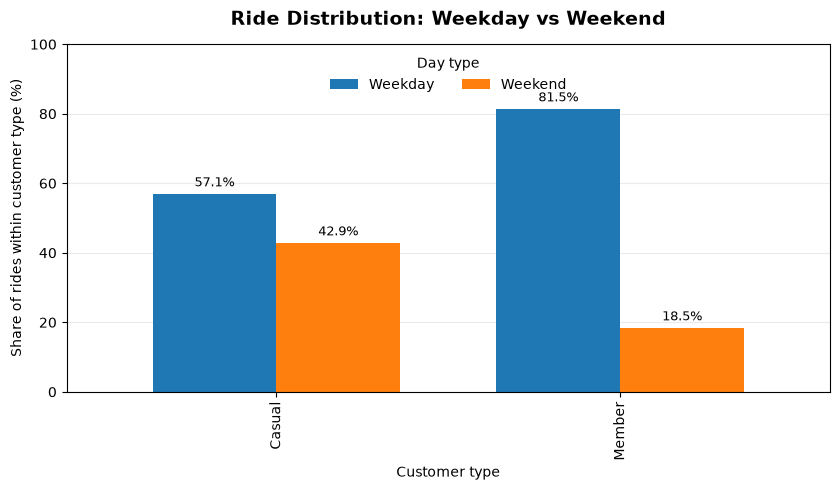

In [13]:
# Compare the share of weekday and weekend rides within each customer type.
import matplotlib.pyplot as plt

weekly_percentages = pd.crosstab(
    data['usertype'], data['day_type'], normalize='index'
) * 100

ax = weekly_percentages[['Weekday', 'Weekend']].plot(
    kind='bar', figsize=(8.5, 5), width=0.72
)
ax.set_title('Ride Distribution: Weekday vs Weekend', pad=14, fontsize=14, weight='bold')
ax.set_xlabel('Customer type')
ax.set_ylabel('Share of rides within customer type (%)')
ax.set_ylim(0, 100)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(title='Day type', frameon=False, ncols=2, loc='upper center')
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)
plt.tight_layout()
plt.show()

### 2. Ride duration

Mean and median ride lengths are shown in minutes. Both measures are higher for casual riders, indicating that their trips tend to last longer than members’ trips.

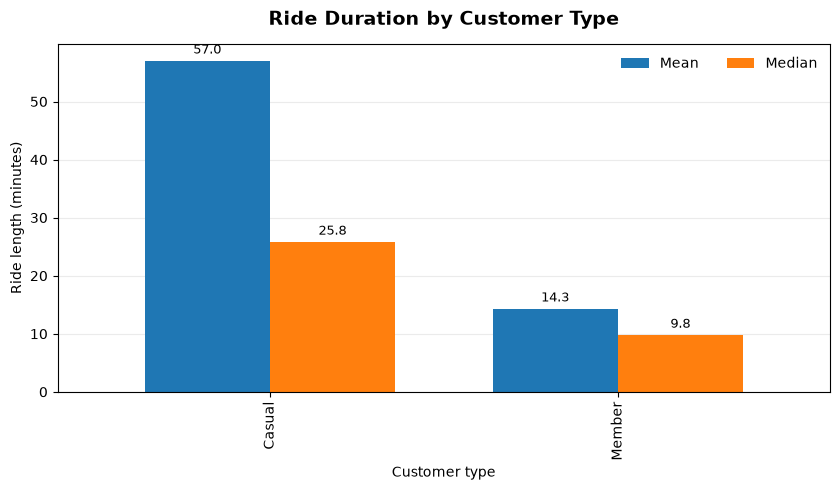

In [14]:
# Compare mean and median ride length. The original ride_length column is in seconds,
# so convert the summary to minutes for easier interpretation.
import matplotlib.pyplot as plt

duration_summary_minutes = (
    data.groupby('usertype')['ride_length'].agg(['mean', 'median']) / 60
)

ax = duration_summary_minutes[['mean', 'median']].plot(
    kind='bar', figsize=(8.5, 5), width=0.72
)
ax.set_title('Ride Duration by Customer Type', pad=14, fontsize=14, weight='bold')
ax.set_xlabel('Customer type')
ax.set_ylabel('Ride length (minutes)')
ax.legend(['Mean', 'Median'], frameon=False, ncols=2, loc='upper right')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3, fontsize=9)
plt.tight_layout()
plt.show()